# House Price Prediction using Machine Learning
### Predictive Analytics Project

**Dataset:** California Housing Dataset (1990 Census) — 20,640 rows, 10 columns
**Source:** Publicly available (originally StatLib repository, also on Kaggle: *camnugent/california-housing-prices*)

**Objective:** Predict the `median_house_value` of a block based on features like income, location, rooms, population etc.

**Steps followed:**
1. Importing libraries & loading data
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Model Building (5 models)
6. Model Comparison — R² Score, MSE, RMSE, MAE
7. Conclusion

## 1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Loading the Dataset

In [2]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
print("Shape of data:", df.shape)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Shape of data: (20640, 10)
Rows: 20640 | Columns: 10


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 3. Data Cleaning
Checking for missing values, duplicates, and outliers.

In [6]:
# missing values
print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total missing: 207


`total_bedrooms` has 207 missing values. Since it is skewed, filling it with **median** is better than mean.

In [7]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())
print("Missing after filling:", df.isnull().sum().sum())

Missing after filling: 0


In [8]:
# duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
# categorical column
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

`ISLAND` has only 5 rows — still keeping it since they are valid data points.

**Capped values:** In this dataset house value is capped at 500001 and housing age at 52. These capped rows can confuse the model, so we remove the capped house values.

In [10]:
print("Rows with capped house value:", (df['median_house_value'] >= 500001).sum())
df = df[df['median_house_value'] < 500001]
print("Shape after removing capped rows:", df.shape)

Rows with capped house value: 965
Shape after removing capped rows: (19675, 10)


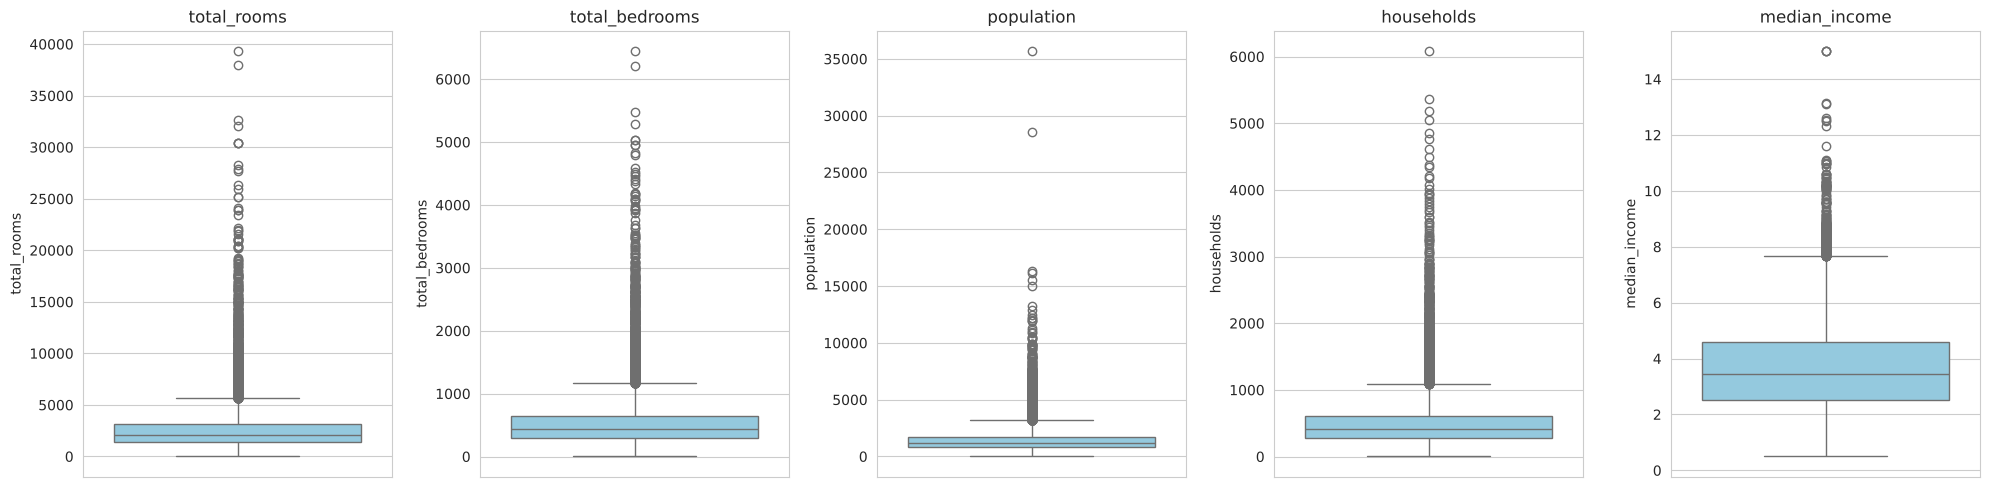

In [11]:
# outliers check using boxplot
num_cols = ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

There are a lot of outliers in rooms, population columns. Removing extreme values using **IQR method** on population (99th percentile cut also works).

In [12]:
Q1 = df['population'].quantile(0.25)
Q3 = df['population'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 3 * IQR   # using 3*IQR so we dont remove too much data
before = df.shape[0]
df = df[df['population'] <= upper]
print("Removed", before - df.shape[0], "outlier rows")
print("Final shape:", df.shape)

Removed 398 outlier rows
Final shape: (19277, 10)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Target Variable

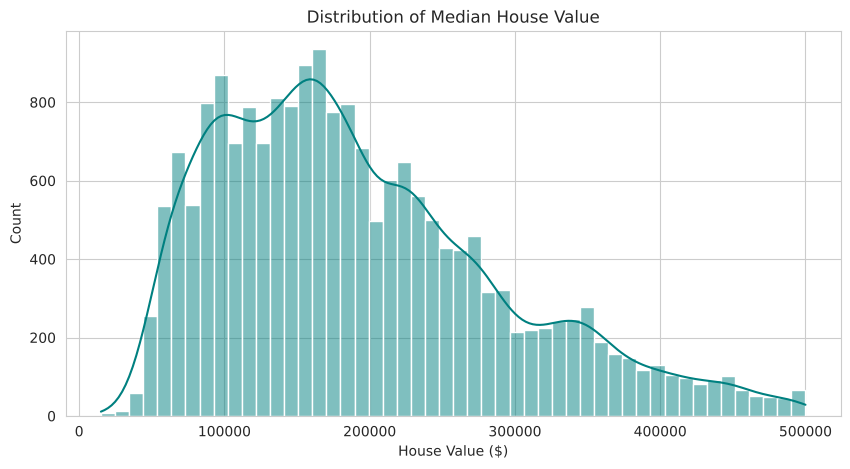

In [13]:
plt.figure(figsize=(10,5))
sns.histplot(df['median_house_value'], bins=50, kde=True, color='teal')
plt.title('Distribution of Median House Value')
plt.xlabel('House Value ($)')
plt.show()

The target is slightly **right skewed** — most houses are between 1 to 3 lakh dollars.

### 4.2 Histograms of all numerical features

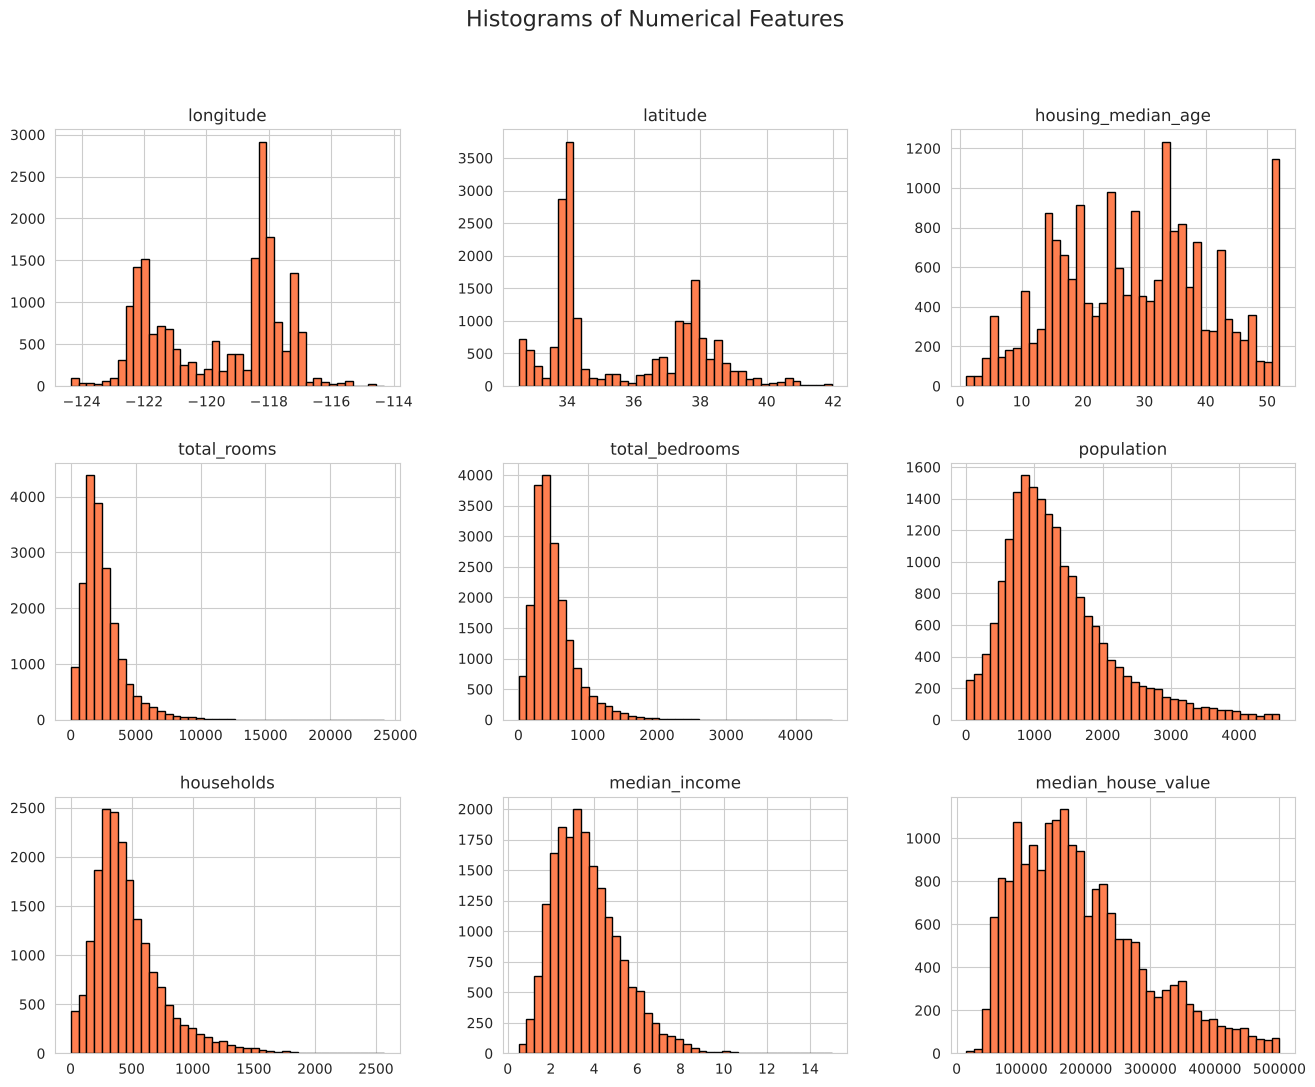

In [14]:
df.hist(bins=40, figsize=(16, 12), color='coral', edgecolor='black')
plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.show()

### 4.3 Correlation Heatmap

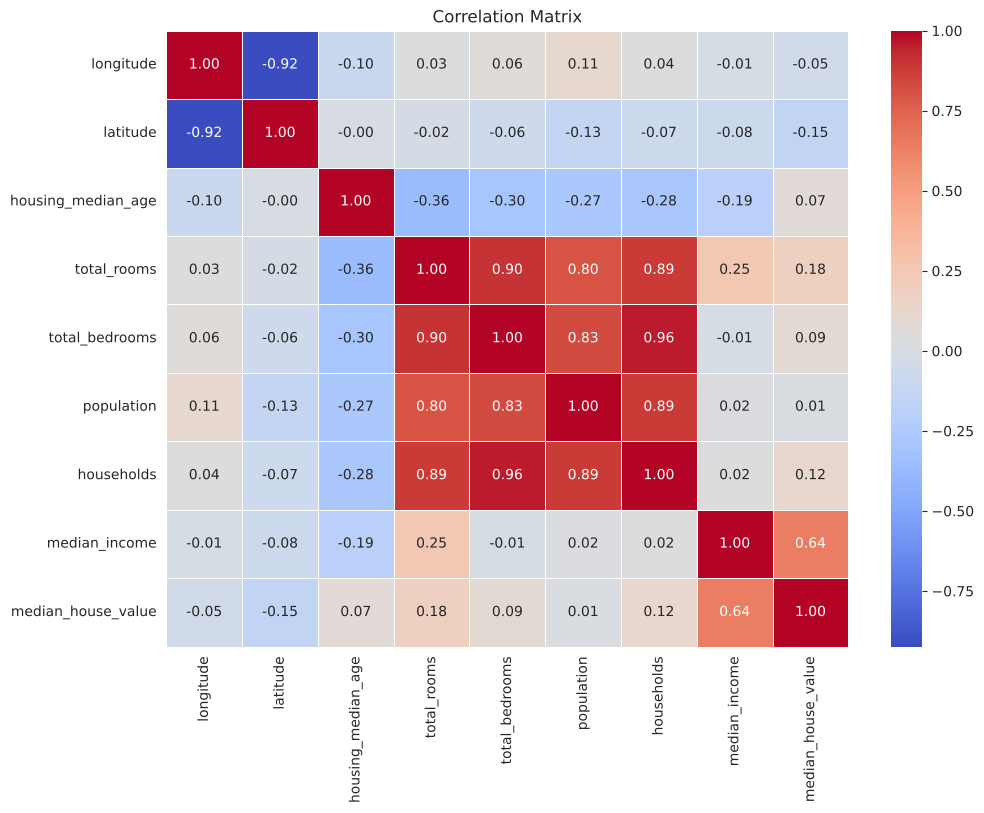

In [15]:
plt.figure(figsize=(11, 8))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

In [16]:
corr['median_house_value'].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.643174
total_rooms           0.180916
households            0.116354
total_bedrooms        0.088642
housing_median_age    0.070473
population            0.012026
longitude            -0.046055
latitude             -0.149452
Name: median_house_value, dtype: float64

**Observation:** `median_income` has the highest correlation (~0.65) with house value. Richer areas = costlier houses, which makes sense.

### 4.4 Income vs House Value

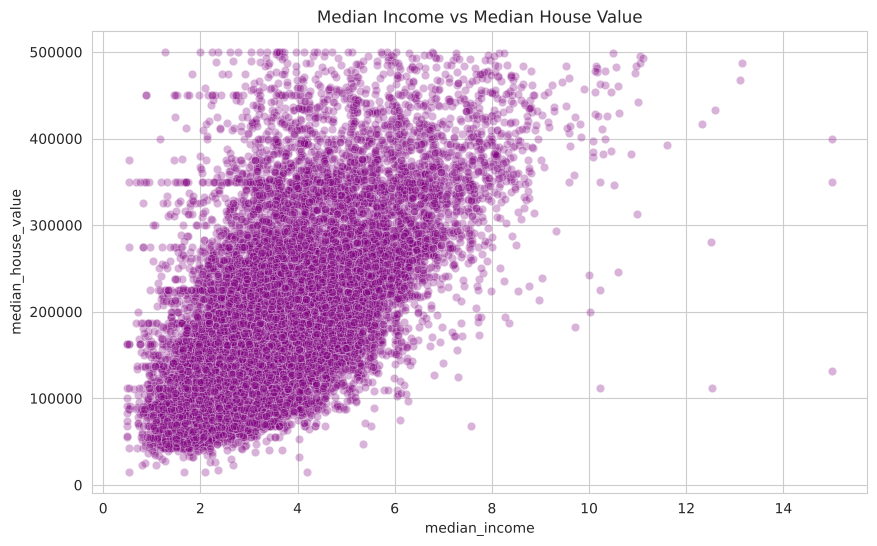

In [17]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.3, color='purple')
plt.title('Median Income vs Median House Value')
plt.show()

### 4.5 Geographical plot (Location vs Price)

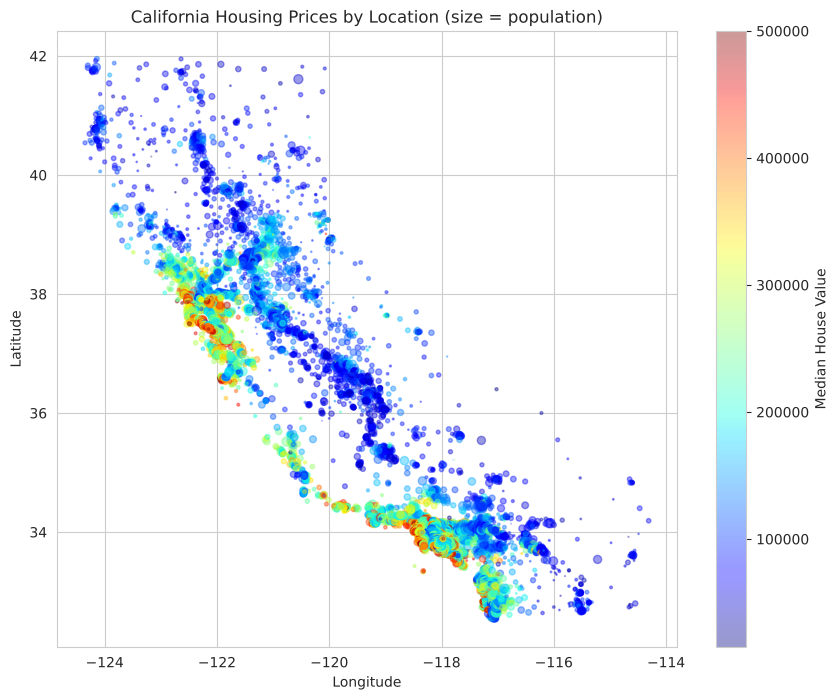

In [18]:
plt.figure(figsize=(10, 8))
plt.scatter(df['longitude'], df['latitude'], alpha=0.4,
            s=df['population']/100, c=df['median_house_value'], cmap='jet')
plt.colorbar(label='Median House Value')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('California Housing Prices by Location (size = population)')
plt.show()

Houses near the coast (Bay Area & Los Angeles) are clearly more expensive.

### 4.6 Ocean Proximity vs House Value

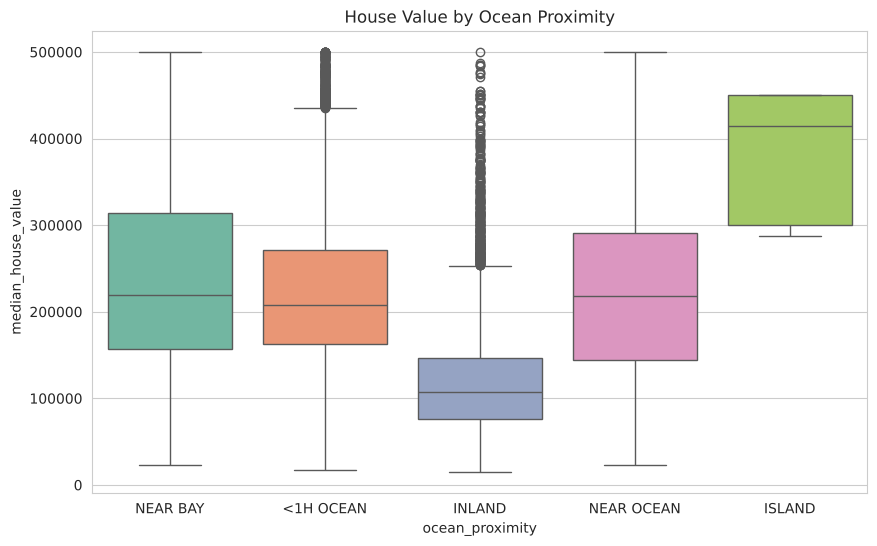

In [19]:
plt.figure(figsize=(10,6))
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df, palette='Set2')
plt.title('House Value by Ocean Proximity')
plt.show()

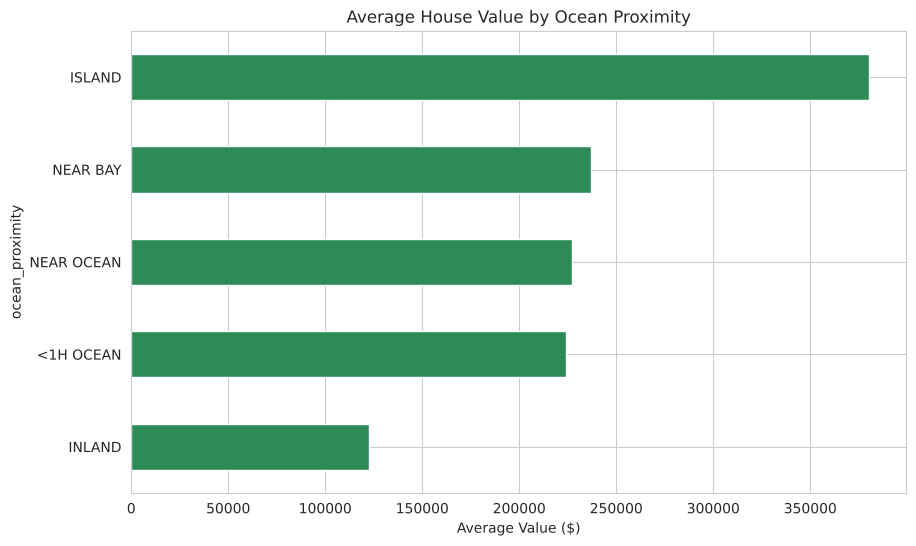

In [20]:
df.groupby('ocean_proximity')['median_house_value'].mean().sort_values().plot(kind='barh', color='seagreen')
plt.title('Average House Value by Ocean Proximity')
plt.xlabel('Average Value ($)')
plt.show()

`INLAND` houses are cheapest. `ISLAND` and `NEAR BAY` are the costliest.

## 5. Feature Engineering
Creating some new meaningful features — total rooms alone doesnt tell much because blocks have different number of households.

In [21]:
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'median_house_value']].corr()['median_house_value']

rooms_per_household         0.108271
bedrooms_per_room          -0.196478
population_per_household   -0.053098
median_house_value          1.000000
Name: median_house_value, dtype: float64

`bedrooms_per_room` has negative correlation — lower ratio means bigger/better houses.

Some blocks have weird ratios (like 1000+ people per household — probably hostels/jails). Clipping these new features at 1st and 99th percentile so linear models dont get affected.

In [22]:
for col in ['rooms_per_household', 'bedrooms_per_room', 'population_per_household']:
    low, high = df[col].quantile(0.01), df[col].quantile(0.99)
    df[col] = df[col].clip(low, high)

df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,19277.000000,19277.000000,19277.000000
mean,5.265823,0.214610,2.929254
std,1.270687,0.053231,0.727379
min,2.594229,0.127295,1.554304
25%,4.413567,0.177640,2.440534
50%,5.178571,0.204797,2.831325
75%,5.963675,0.241319,3.299525
max,10.389867,0.415480,5.323748


In [23]:
# One Hot Encoding for ocean_proximity
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True, dtype=int)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,6.984127,0.146591,2.555556,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,6.238137,0.155797,2.109842,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,8.288136,0.129516,2.802260,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,5.817352,0.184458,2.547945,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,6.281853,0.172096,2.181467,0,0,1,0


## 6. Train Test Split & Scaling

In [24]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (15421, 15)
Testing data: (3856, 15)


In [25]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

## 7. Model Building
Using 5 regression models:
1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. XGBoost Regressor

In [26]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    train_r2 = r2_score(y_train, model.predict(X_train_sc))

    results.append([name, round(train_r2, 4), round(r2, 4), round(mse, 2), round(rmse, 2), round(mae, 2)])
    print(f"{name} done  ->  R2 = {r2:.4f}")

Linear Regression done  ->  R2 = 0.6345
Ridge Regression done  ->  R2 = 0.6345
Decision Tree done  ->  R2 = 0.6799


Random Forest done  ->  R2 = 0.7906


XGBoost done  ->  R2 = 0.8280


## 8. Model Comparison Table

In [27]:
results_df = pd.DataFrame(results, columns=['Model', 'Train R2', 'Test R2 Score (Accuracy)', 'MSE', 'RMSE', 'MAE'])
results_df['Accuracy (%)'] = (results_df['Test R2 Score (Accuracy)'] * 100).round(2)
results_df = results_df.sort_values('Test R2 Score (Accuracy)', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df

,Model,Train R2,Test R2 Score (Accuracy),MSE,RMSE,MAE,Accuracy (%)
1,XGBoost,0.9307,0.8280,1.750858e+09,41843.25,28179.25,82.80
2,Random Forest,0.9706,0.7906,2.131648e+09,46169.77,31039.82,79.06
3,Decision Tree,0.8292,0.6799,3.257960e+09,57078.55,38649.33,67.99
4,Linear Regression,0.6457,0.6345,3.720017e+09,60991.94,44656.14,63.45
5,Ridge Regression,0.6457,0.6345,3.719933e+09,60991.25,44655.16,63.45


> Note: For regression problems, **R² score** is used as the measure of accuracy (how much % of variance in price the model explains).

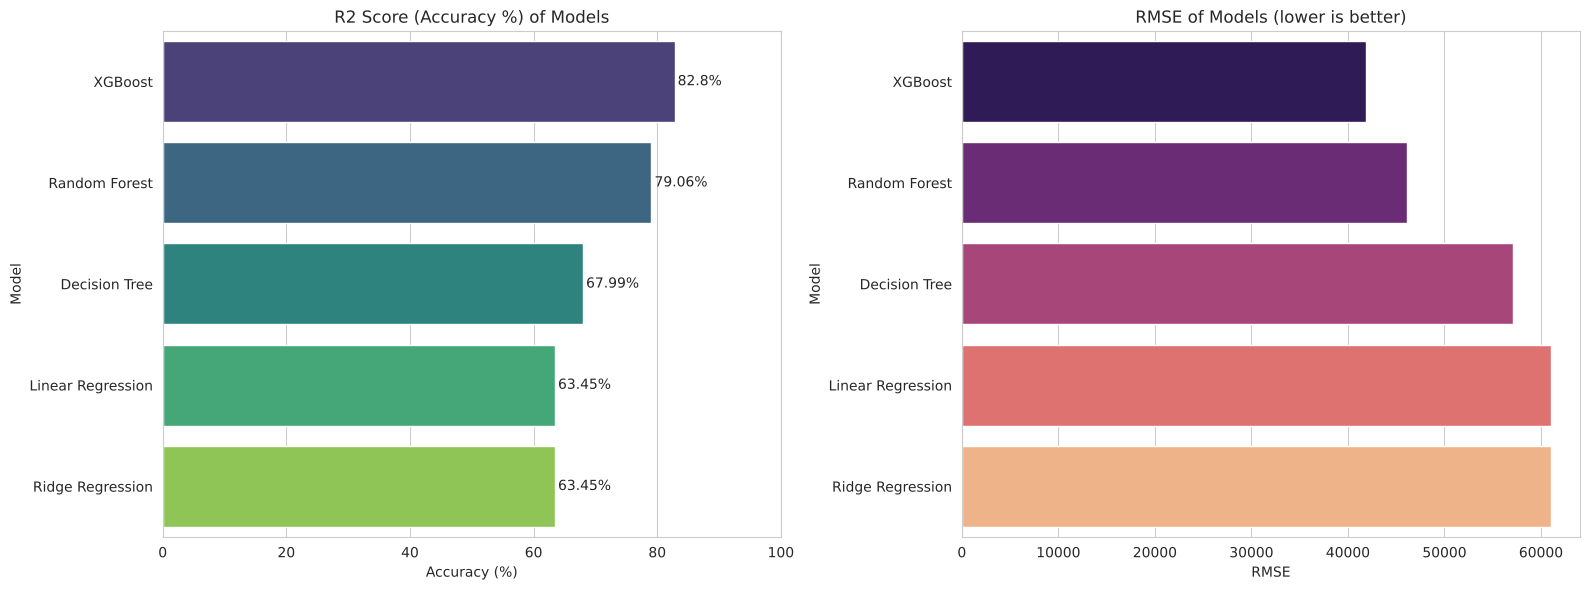

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='Accuracy (%)', y='Model', data=results_df, ax=axes[0], palette='viridis')
axes[0].set_title('R2 Score (Accuracy %) of Models')
for i, v in enumerate(results_df['Accuracy (%)']):
    axes[0].text(v + 0.5, i, str(v) + '%', va='center')
axes[0].set_xlim(0, 100)

sns.barplot(x='RMSE', y='Model', data=results_df, ax=axes[1], palette='magma')
axes[1].set_title('RMSE of Models (lower is better)')

plt.tight_layout()
plt.show()

### Cross Validation (to check the results are stable)

In [29]:
cv_scores = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_sc, y_train, cv=5, scoring='r2', n_jobs=-1)
    cv_scores.append([name, round(scores.mean(), 4), round(scores.std(), 4)])

cv_df = pd.DataFrame(cv_scores, columns=['Model', 'CV Mean R2', 'CV Std'])
cv_df

,Model,CV Mean R2,CV Std
0,Linear Regression,0.6442,0.0187
1,Ridge Regression,0.6442,0.0187
2,Decision Tree,0.6604,0.0091
3,Random Forest,0.7792,0.0122
4,XGBoost,0.8165,0.0121


## 9. Actual vs Predicted (Best Model)

Best model: XGBoost


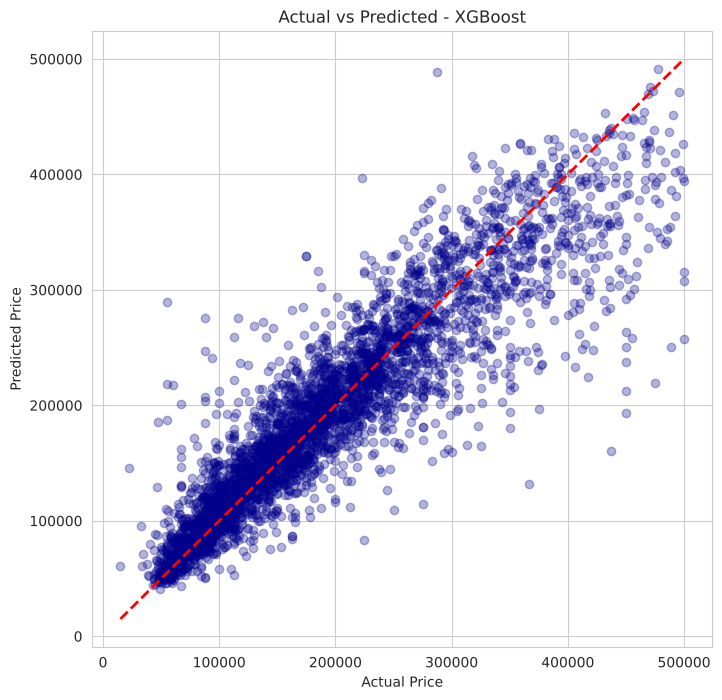

In [30]:
best = results_df.iloc[0]['Model']
print("Best model:", best)

plt.figure(figsize=(8, 8))
plt.scatter(y_test, predictions[best], alpha=0.3, color='darkblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title(f'Actual vs Predicted - {best}')
plt.show()

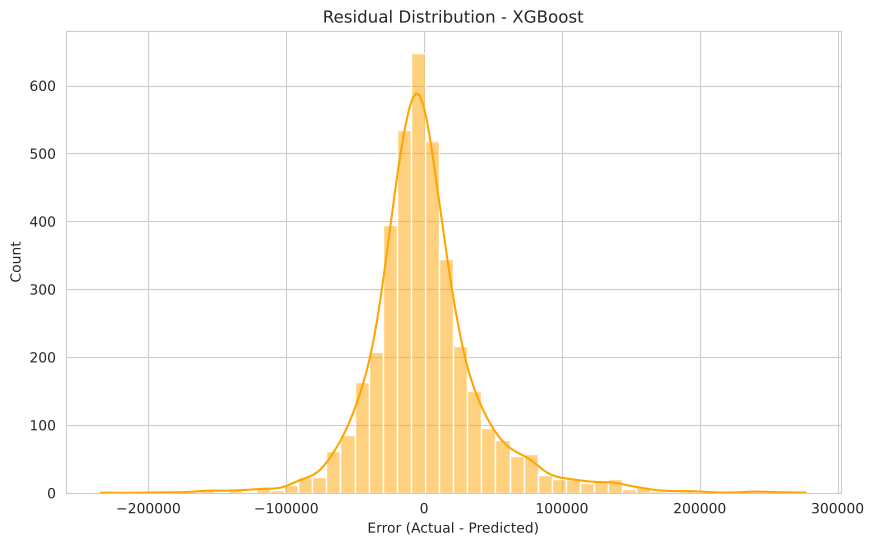

In [31]:
# residual plot
residuals = y_test - predictions[best]
sns.histplot(residuals, bins=50, kde=True, color='orange')
plt.title(f'Residual Distribution - {best}')
plt.xlabel('Error (Actual - Predicted)')
plt.show()

## 10. Feature Importance

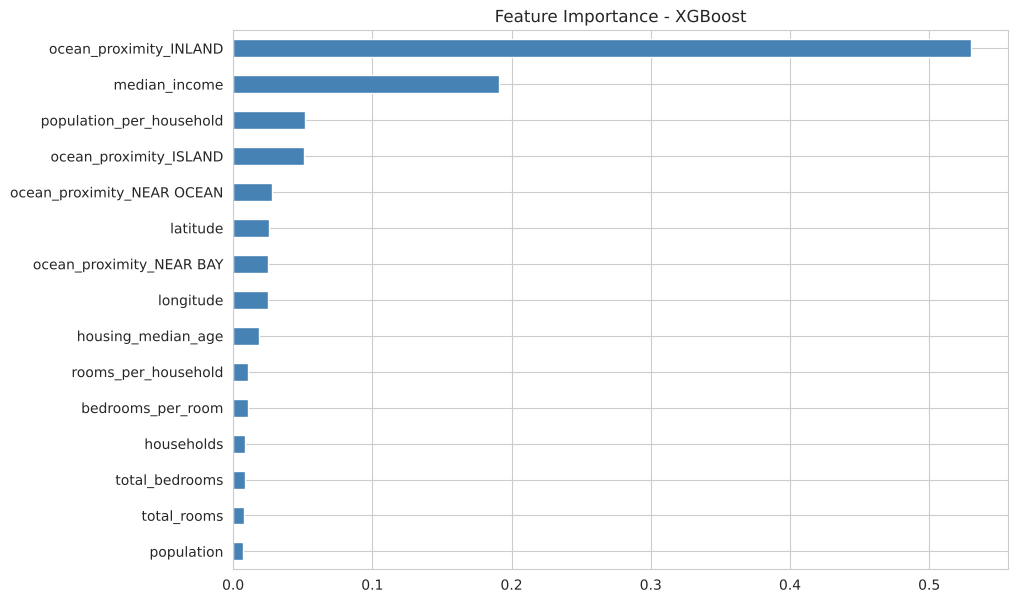

In [32]:
fi = pd.Series(models[best].feature_importances_, index=X.columns).sort_values()
fi.plot(kind='barh', figsize=(10, 7), color='steelblue')
plt.title(f'Feature Importance - {best}')
plt.show()

## 11. Sample Prediction

In [33]:
sample = X_test.iloc[:5]
pred = models[best].predict(scaler.transform(sample))
pd.DataFrame({'Actual': y_test.iloc[:5].values, 'Predicted': pred.round(0)})

,Actual,Predicted
0,201400.0,209277.0
1,102100.0,80326.0
2,100400.0,130922.0
3,60000.0,68131.0
4,227100.0,231076.0


## 12. Conclusion

- Dataset had **20,640 rows**. After cleaning (missing values filled, capped values and extreme outliers removed) we used **19,277 rows**.
- **Median income** and **location (ocean proximity, lat/long)** are the most important factors deciding house price.
- Linear models (Linear & Ridge) give the lowest R² — the relationship between features and price is not purely linear.
- Decision Tree improved the score but shows overfitting (train R² much higher than test R²).
- Ensemble models performed best — **XGBoost** gave the highest R² score with lowest MSE/RMSE, followed by Random Forest.
- Cross validation scores are close to test scores, so the models are not just lucky on one split.

**Future scope:** Hyperparameter tuning with GridSearchCV, trying LightGBM / CatBoost, and deploying the model using Streamlit.